#Câu 1 Khai báo thư viện và đọc dữ liệu, thống kê số lượng

In [30]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# 1. Nhập dữ liệu đầu vào
# Đặt tên các cột theo tập Adult Income chuẩn
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

train_data = pd.read_csv('adult.data.csv', names=columns, sep=r',\s*', engine='python')
test_data = pd.read_csv('adult.test.csv', names=columns, sep=r',\s*', engine='python', skiprows=1)

print(f"Số lượng dữ liệu huấn luyện ban đầu: {len(train_data)}")
print(f"Số lượng dữ liệu kiểm thử ban đầu: {len(test_data)}")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Số lượng dữ liệu huấn luyện ban đầu: 32562
Số lượng dữ liệu kiểm thử ban đầu: 16281


#Câu 2 Tiền xử lý dữ liệu và nối tập dữ liệu

In [32]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 1. Định nghĩa đúng số lượng cột cho từng file
train_cols = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

# File test không có cột fnlwgt (chỉ có 14 cột)
test_cols = [
    'age', 'workclass', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

# Đọc file với đúng danh sách cột tương ứng
train_data = pd.read_csv('adult.data.csv', names=train_cols, skipinitialspace=True)
test_data = pd.read_csv('adult.test.csv', names=test_cols, skipinitialspace=True, skiprows=1)

# Chuẩn hóa nhãn income ở tập test (xóa dấu chấm thừa ở cuối)
test_data['income'] = test_data['income'].astype(str).str.rstrip('.')

# 2. Xóa các dòng chứa dấu '?' và dropna
train_data = train_data.replace('?', np.nan).dropna().reset_index(drop=True)
test_data = test_data.replace('?', np.nan).dropna().reset_index(drop=True)

# Lọc bỏ dòng tiêu đề hoặc dòng lỗi phát sinh (nếu có)
train_data = train_data[pd.to_numeric(train_data['age'], errors='coerce').notnull()].reset_index(drop=True)
test_data = test_data[pd.to_numeric(test_data['age'], errors='coerce').notnull()].reset_index(drop=True)

print(f"Number of training data: {len(train_data)}")
print(f"Number of test data: {len(test_data)}")

# 3. Xóa cột 'fnlwgt' trong dữ liệu huấn luyện
train_data.drop('fnlwgt', axis=1, inplace=True, errors='ignore')

# 4. Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train_data, test_data], ignore_index=True)

# 5. Ép kiểu int64 cho 5 thuộc tính số định lượng
num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for col in num_cols:
    data[col] = data[col].astype('int64')

data.info()

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Number of training data: 30162
Number of test data: 15060
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  45222 non-null  int64 
 12  native-country  45222 non-null  object
 13  income          45222 non-null  object
dtypes: int64(5), object(9)
memory usage: 4.8+ 

#Câu 3 Khảo sát độ tương đồng Pearson bằng đồ thị Heatmap

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


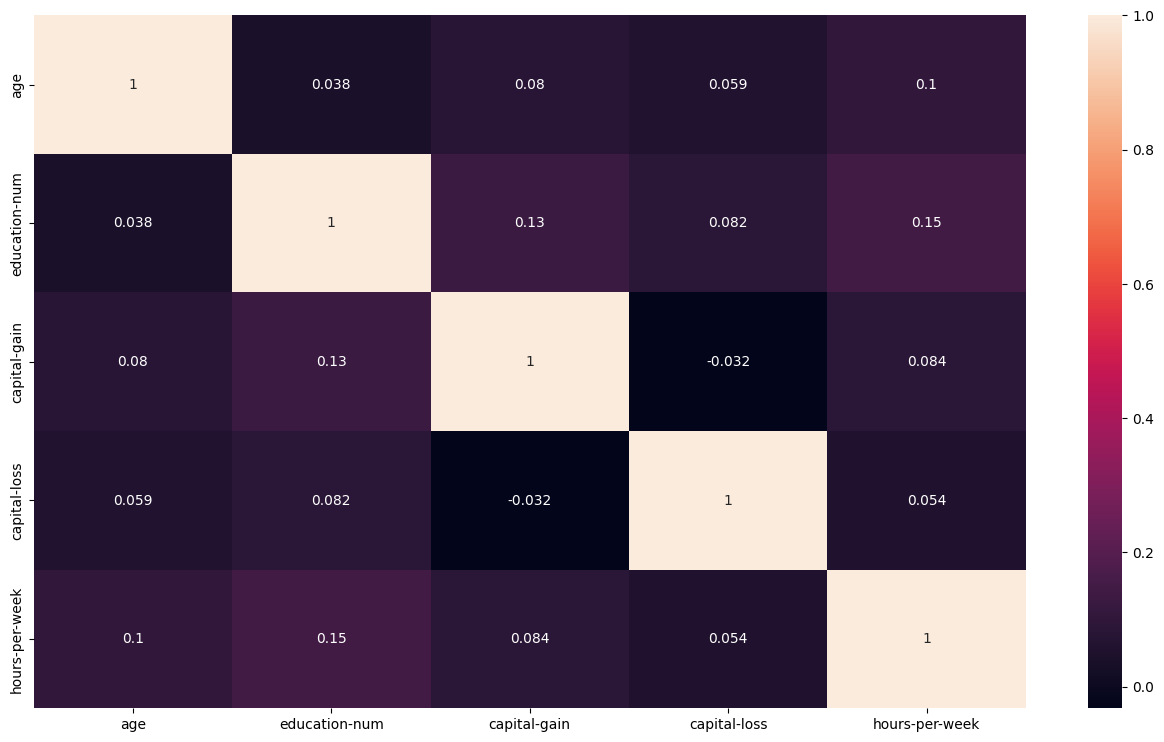

In [33]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Ép kiểu chuẩn cho 5 thuộc tính số trong tập Adult Income
num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for col in num_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

# 2. Vẽ biểu đồ heatmap tương quan Pearson theo đúng mẫu giáo trình
plt.figure(figsize=(16, 9))
sns.heatmap(data[num_cols].corr(method='pearson'), annot=True)
plt.show()

#Câu 4 Tách features và labels

In [34]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 4. Tách thuộc tính bình thường và thuộc tính quyết định 'income'
features = data.drop('income', axis=1)
labels = data['income']

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels: {labels.shape}")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước features: (45222, 13)
Kích thước labels: (45222,)


#Câu 5 Chuyển đổi các cột phân loại về dạng One-Hot Vector

In [35]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Xác định các cột phân loại (dạng object) theo mẫu giáo trình[cite: 10, 17]
cat_cols = features.select_dtypes(exclude=['int64']).columns
print("features.select_dtypes(exclude=['int64']).columns:")
print(cat_cols)

# Chuyển đổi get_dummies với dtype=int để ra giá trị 0 và 1[cite: 11, 17]
features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
display(features_onehot)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
features.select_dtypes(exclude=['int64']).columns:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45218,39,13,0,0,36,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45219,38,13,0,0,50,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45220,44,13,5455,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0


#Câu 6 Tách lại dữ liệu Train và Test như ban đầu

In [36]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 6. Tách theo số lượng dòng huấn luyện ban đầu (30162 dòng)
X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

print(f"Kích thước tập Train: {X_train.shape}, {y_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}, {y_test.shape}")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước tập Train: (30162, 103), (30162,)
Kích thước tập Test: (15060, 103), (15060,)


#Câu 7 Xây dựng cây quyết định ID3 (Entropy) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy: 0.8175298804780876
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



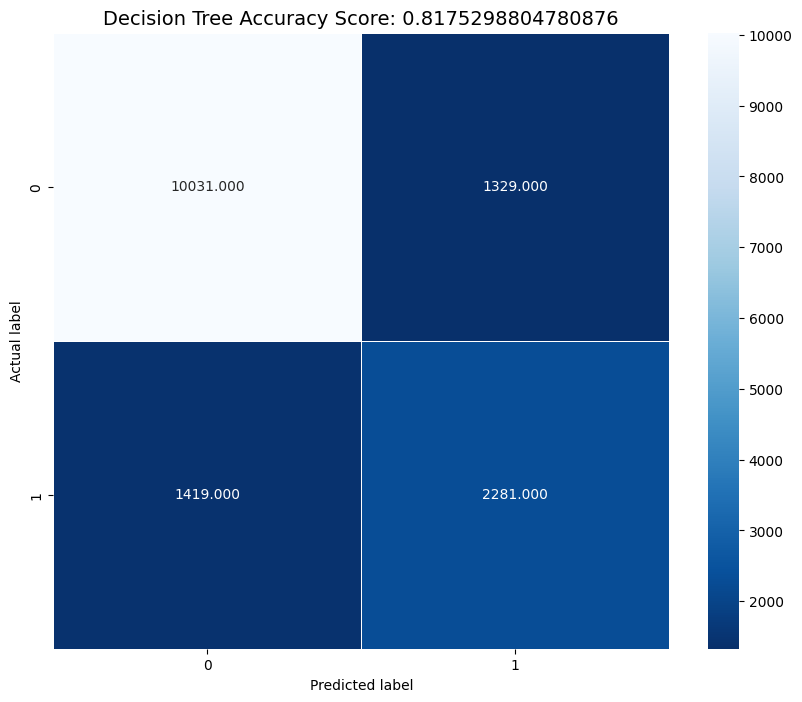

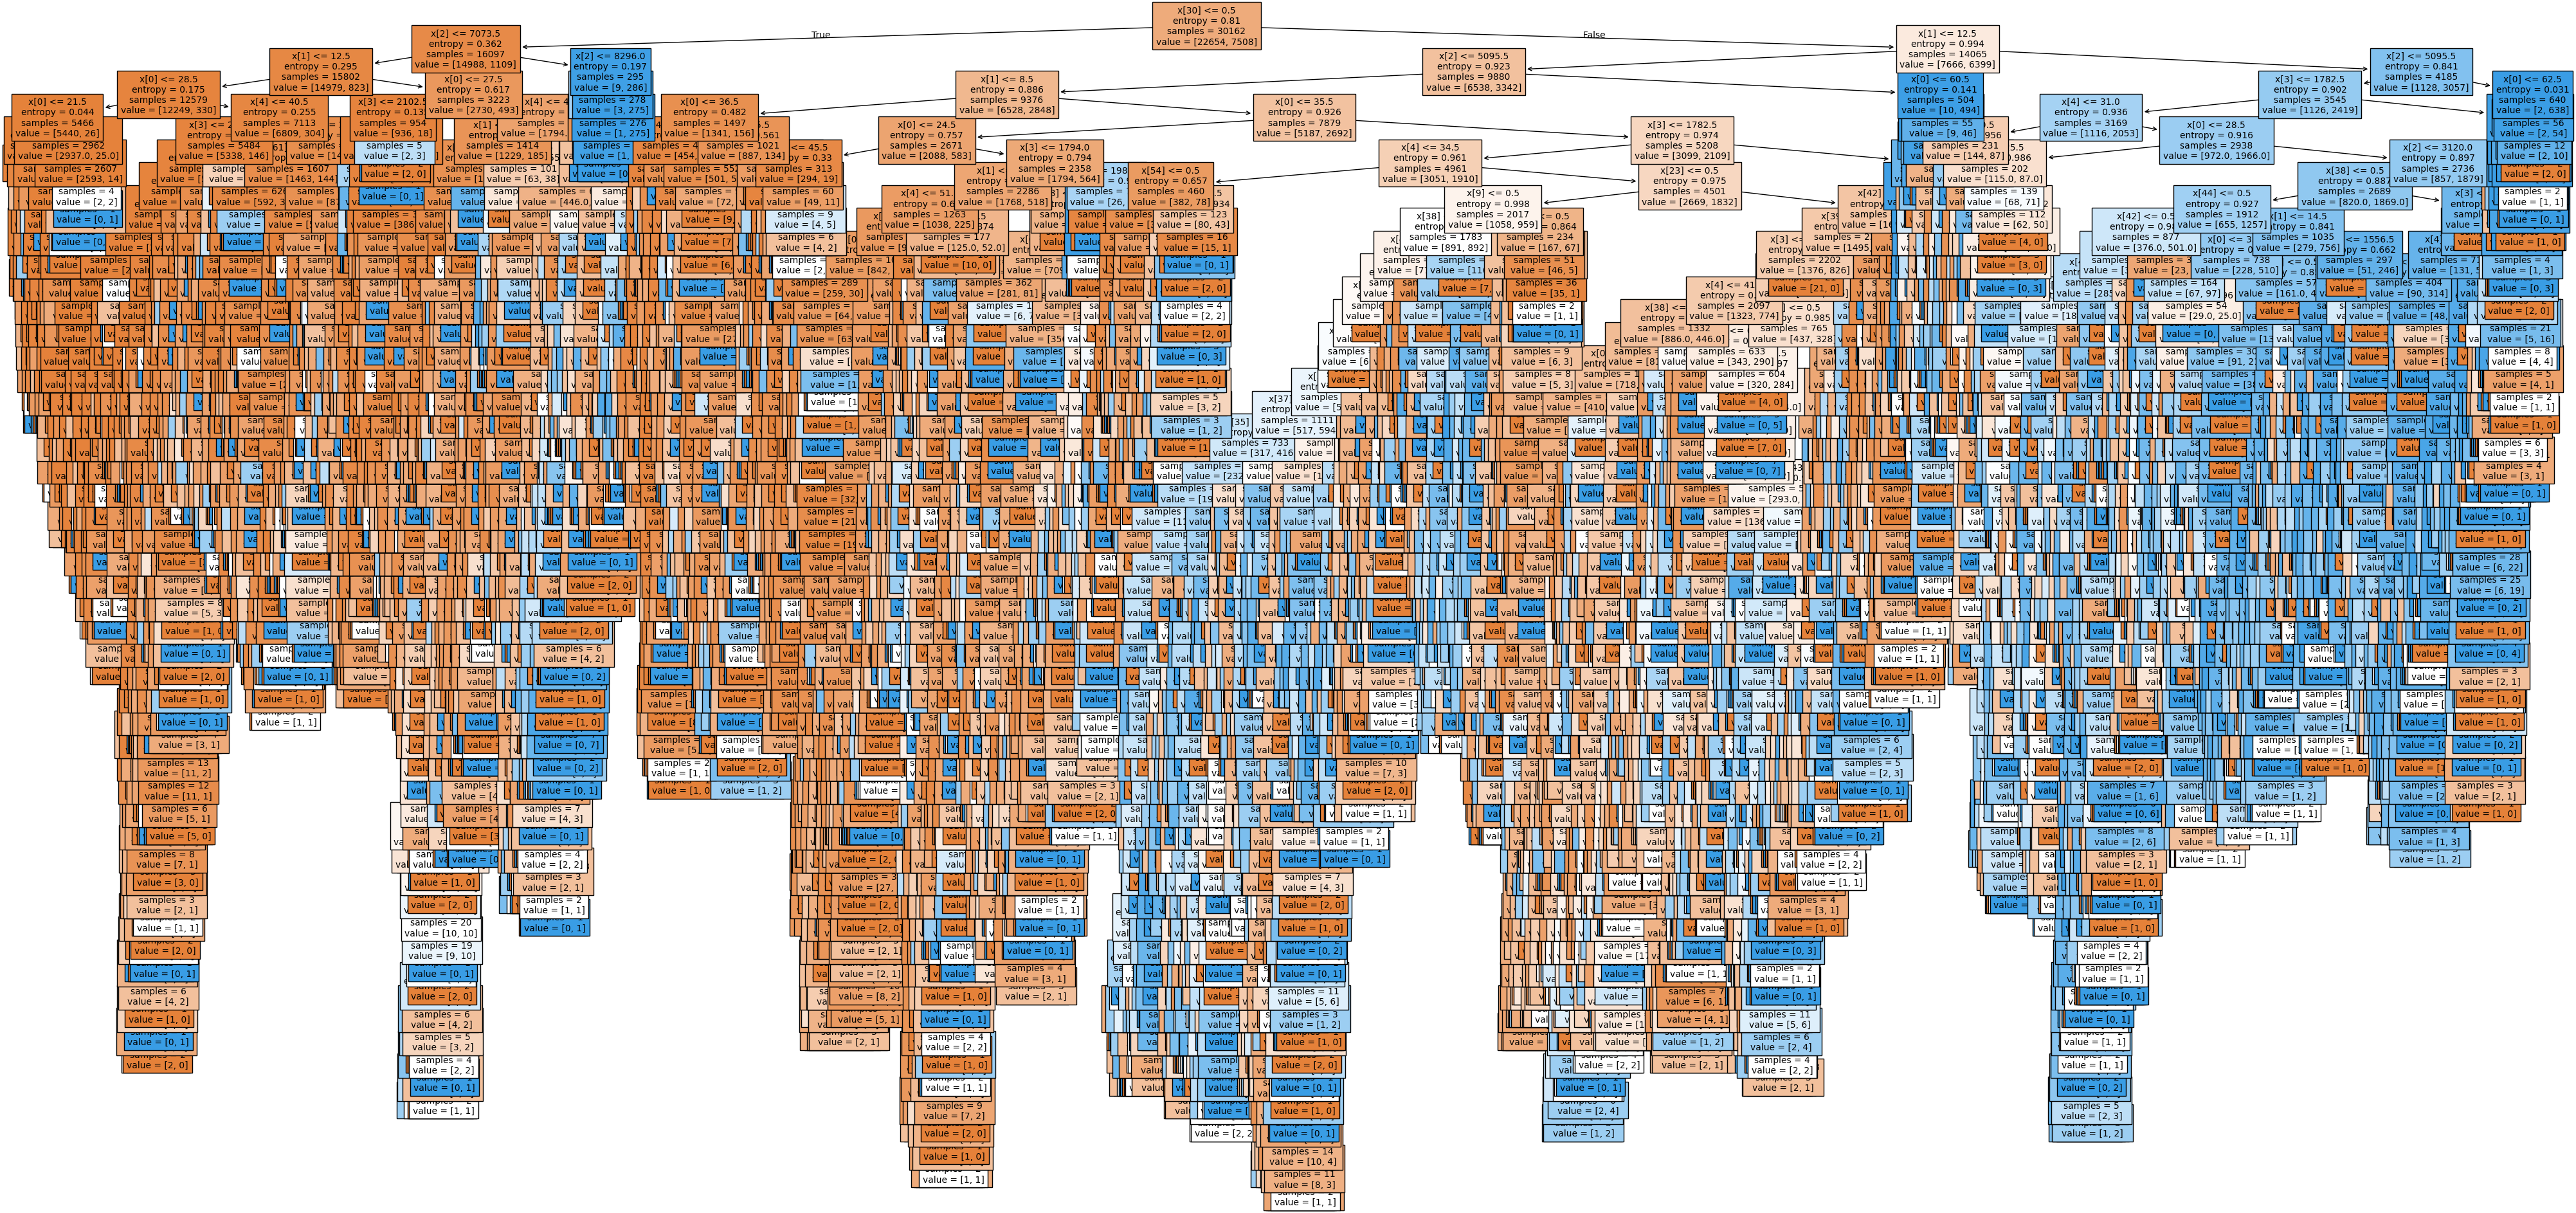

In [37]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn import tree, metrics

# 1. Huấn luyện cây ID3 (criterion="entropy")
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

# 2. Đánh giá mô hình trên tập kiểm thử
tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# 3. Tính toán ma trận nhầm lẫn và vẽ heatmap
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree Accuracy Score: {tree_score}', size=14)
plt.show()

# 4. Biểu diễn cây ID3 và lưu ra file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree.png', dpi=100)
plt.show()

#Câu 8 Xây dựng cây quyết định CART (Gini) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (CART): 0.8122841965471448
Report:
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



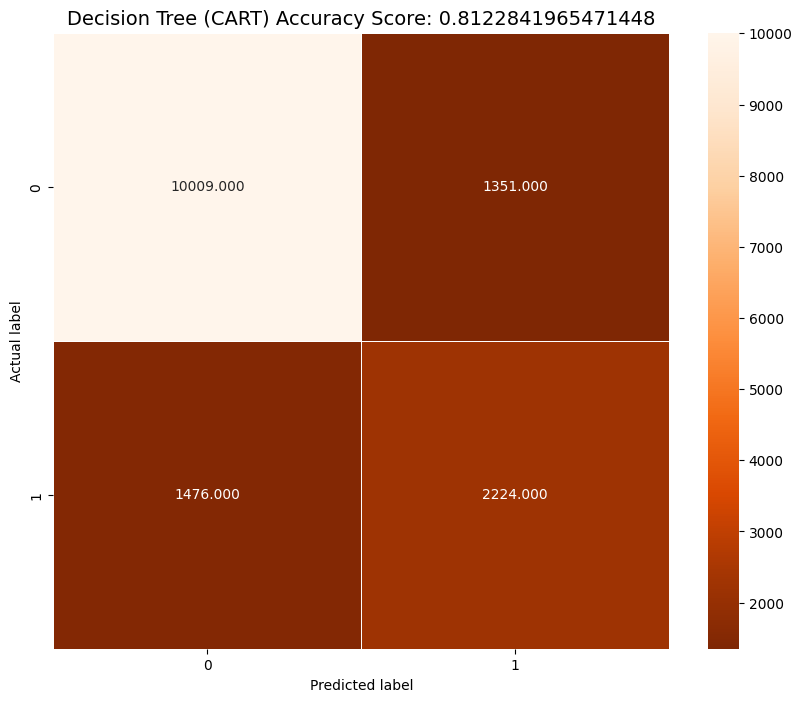

In [38]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 8. Xây dựng cây CART (criterion='gini')
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Đánh giá kết quả
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Oranges_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Accuracy Score: {cart_score}', size=14)
plt.show()

#Câu 9 Xây dựng mô hình Naïve Bayes (GaussianNB) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (Naïve Bayes): 0.8029216467463479
Report:
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



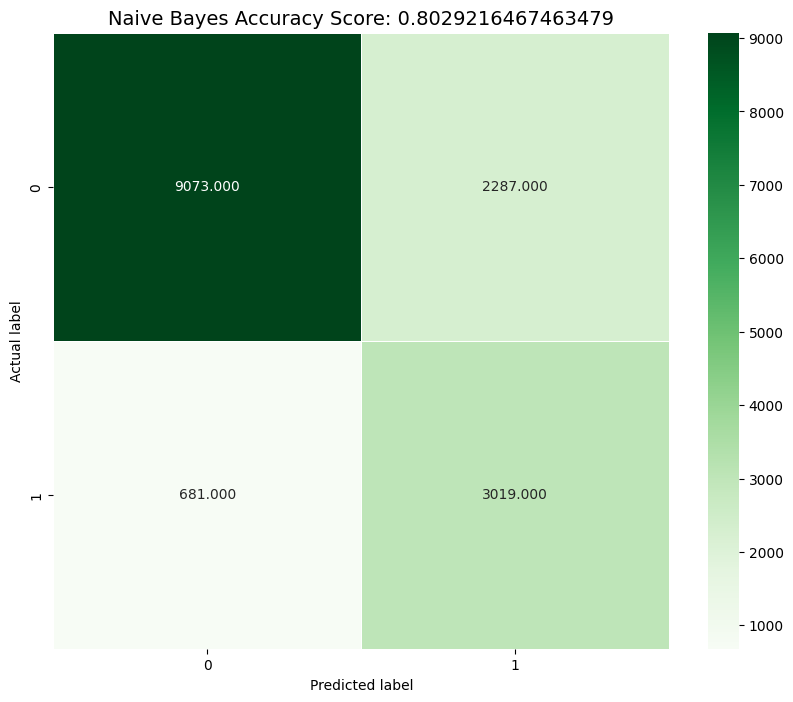

In [39]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 9. Huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

# Ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score}', size=14)
plt.show()

#Câu 10 So sánh kết quả của các mô hình

In [40]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 10. Tổng hợp và so sánh kết quả các mô hình
comparison_df = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3)', 'Decision Tree (CART)', 'Naïve Bayes'],
    'Accuracy': [tree_score, cart_score, bayes_score],
    'Precision (<=50K)': [
        metrics.precision_score(y_test, tree_pred, pos_label='<=50K'),
        metrics.precision_score(y_test, cart_pred, pos_label='<=50K'),
        metrics.precision_score(y_test, bayes_pred, pos_label='<=50K')
    ],
    'Recall (<=50K)': [
        metrics.recall_score(y_test, tree_pred, pos_label='<=50K'),
        metrics.recall_score(y_test, cart_pred, pos_label='<=50K'),
        metrics.recall_score(y_test, bayes_pred, pos_label='<=50K')
    ],
    'F1-score (<=50K)': [
        metrics.f1_score(y_test, tree_pred, pos_label='<=50K'),
        metrics.f1_score(y_test, cart_pred, pos_label='<=50K'),
        metrics.f1_score(y_test, bayes_pred, pos_label='<=50K')
    ]
})

print("--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---")
display(comparison_df)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---


,Mô hình,Accuracy,Precision (<=50K),Recall (<=50K),F1-score (<=50K)
0,Decision Tree (ID3),0.817530,0.876070,0.883011,0.879527
1,Decision Tree (CART),0.812284,0.871485,0.881074,0.876253
2,Naïve Bayes,0.802922,0.930182,0.798680,0.859430
